# Predicting TB Drug Resistance from Genomic Mutations
## Stages 2 and 3: Data Identification, Preparation and Exploration

**Project:** Genomic prediction of drug resistance in *Mycobacterium tuberculosis*
**Group members:** _add names here_
**Track:** Genomics (DNA-level variant data linked to laboratory phenotypes)

This notebook covers Stage 2 (identifying and justifying the dataset) and Stage 3 (preparing and exploring it).
It does not train any models. Its job is to understand the data well enough to plan the modelling stage.

**Running it:** the notebook is self-contained. In Google Colab, choose *Runtime → Run all*.
The first code section downloads about 1.5 GB from the EMBL-EBI public FTP site (no login needed), which takes a few minutes.
If the files are already on disk (for example in the project repository's `data/raw/cryptic/` folder), they are used instead of downloading again.

# Stage 2: Data Identification

## 2.1 Project context

Tuberculosis (TB) is one of the leading infectious causes of death worldwide.
Kenya is on the World Health Organization's list of 30 high-burden countries for TB and for TB/HIV co-infection [1].
Drug-resistant TB is a major obstacle to treatment.
Multidrug-resistant TB (MDR-TB, resistance to at least **rifampicin** and **isoniazid**) needs longer, more toxic and more expensive regimens.
WHO estimates that MDR/RR-TB caused about 150,000 deaths in 2024 [1].

The standard way to find resistance is phenotypic drug-susceptibility testing (DST): culture the bacteria with the drug and see whether they grow.
*M. tuberculosis* grows slowly, so culture-based DST takes weeks.
Whole-genome sequencing (WGS) is faster, and most resistance comes from mutations in a few well-known genes [2, 3]:

| Drug | Drug class | Main resistance genes | Mechanism |
|---|---|---|---|
| Rifampicin (RIF) | First-line, rifamycin | `rpoB` | Mutations in the RNA polymerase β-subunit, mostly in the 81-bp "RRDR" hotspot (codons 426–452) |
| Isoniazid (INH) | First-line | `katG`, `inhA`, `fabG1`–`inhA` promoter | Loss of the KatG enzyme that activates the drug (e.g. `katG` S315T), or overexpression of the drug target InhA |
| Levofloxacin (LEV), Moxifloxacin (MXF) | Second-line, fluoroquinolones | `gyrA` | Mutations in DNA gyrase, mostly in the "QRDR" (codons 88–94) |

**Research question:** *Can mutations in established resistance-associated genes accurately predict phenotypic drug resistance in M. tuberculosis isolates, and which mutations contribute most to prediction across different drug classes?*

To answer this we need a dataset in which the **same isolates** have both (a) their genome sequenced and variants called, and (b) a laboratory-measured resistance result for each drug.
We plan to model this as one binary classification task per drug: input = presence/absence of each mutation in the gene panel, output = resistant (1) or susceptible (0).

## 2.2 Dataset description

| Item | Details |
|---|---|
| **Dataset name** | CRyPTIC data compendium, `release_june2022` ("Release 1.1" data tables, cryptic-analysis-group) |
| **Database / repository** | CRyPTIC Consortium (Comprehensive Resistance Prediction for Tuberculosis: an International Consortium), hosted on the EMBL-EBI public FTP server |
| **URL** | https://ftp.ebi.ac.uk/pub/databases/cryptic/release_june2022/ (tables under `reproducibility/data_tables/cryptic-analysis-group/`) |
| **Accessions** | Each sequenced isolate has an ENA (European Nucleotide Archive) run accession, listed in the `ENA` column of `GENOMES` |
| **Primary citation** | The CRyPTIC Consortium (2022), *PLoS Biology* 20(8): e3001721 [4] |
| **Type of biological data** | Genomic: SNPs and indels called from Illumina whole-genome sequencing against the H37Rv reference genome (NC_000962.3). Phenotypic: minimum inhibitory concentrations (MICs) measured on 96-well UKMYC5/UKMYC6 broth-microdilution plates, converted to resistant/susceptible calls using epidemiological cut-offs (ECOFFs) [5] |
| **Access** | Open, anonymous download. No registration or data-access agreement |

The release is a set of linked tables that share the isolate identifier `UNIQUEID`. We use four of them:

| File | Size | Records | Relevant fields |
|---|---|---|---|
| `UKMYC_PHENOTYPES.csv.gz` | 4 MB | 228,650 rows: 17,050 isolates × up to 14 drugs | `UNIQUEID`, `DRUG`, `MIC`, `BINARY_PHENOTYPE` (R/S/I), `PHENOTYPE_QUALITY` (HIGH/MEDIUM/LOW), `READINGDAY`, `PLATEDESIGN` |
| `MUTATIONS.csv.gz` | 1.5 GB | 88,172,303 rows: one per isolate × variant (difference from the reference), whole genome | `UNIQUEID`, `GENE`, `MUTATION` (e.g. `S450L`, `c-15t`), `AMINO_ACID_NUMBER`, `NUCLEOTIDE_NUMBER`, `IS_SNP`, `IS_INDEL`, `IN_PROMOTER`, `IS_NULL` (no confident call), `IS_FILTER_PASS`, `IS_HET` |
| `GENOMES.csv.gz` | 5 MB | 77,860 sequenced isolates | `UNIQUEID`, `SPECIES`, `MYKROBE_LINEAGE_NAME_1/2` (phylogenetic lineage), `N_SNP`, `N_NULL`, `ENA` |
| `SAMPLES.csv.gz` | 0.25 MB | 16,669 patient samples | `SITEID`, `SUBJID`, `LABID` (joinable to `GENOMES`), `COUNTRY_WHERE_SAMPLE_TAKEN`, `COLLECTION_DATE` |

After joining these tables (§3.1), **12,477 isolates** have both a genome and phenotypes, and 1,553 distinct mutations occur in our five panel genes.

The release covers 14 drugs. We use only the four whose main resistance genes are well established and whose genes we include in our panel: RIF, INH, LEV and MXF.
Pyrazinamide (and its gene `pncA`) is **not available**: the UKMYC plates do not test it.

## 2.3 Why this dataset fits the project

1. **It links genotype to phenotype for the same isolates.** This is the core need of the research question. Every isolate has a variant table *and* an MIC for each drug, joined by one key (`UNIQUEID`), so we do not have to match samples across separate studies.
2. **It is large and diverse.** It has 12,477 sequenced and phenotyped isolates from at least 21 countries on four continents, including about 1,760 from Africa (mostly South Africa, plus Burkina Faso, Algeria, Nigeria and Tunisia). That is enough to have many resistant *and* susceptible isolates for each drug, which a classifier needs.
3. **The phenotypes are measured consistently.** All isolates were tested on the same plate design and read using standardised methods. Binary R/S labels were derived using published ECOFFs [5], so labels are comparable across laboratories.
4. **The variants are already called and annotated.** The CRyPTIC pipeline maps reads to H37Rv and annotates each variant with its gene and amino-acid change. We can build the isolate × mutation matrix directly, without re-processing raw sequencing reads.
5. **It records data quality.** Null calls, failed filters, phenotype quality and lineage are all provided, so we can measure data quality instead of assuming it.
6. **It is openly available and citable**, which makes the analysis reproducible.

**How it addresses the research question:** for each drug, each isolate becomes one row with a 0/1 column per mutation in `rpoB`, `katG`, `inhA`, the `fabG1`–`inhA` promoter and `gyrA`, plus a 0/1 resistance label.
Comparing mutation frequencies between resistant and susceptible isolates (this notebook), and later training classifiers on these matrices, tells us how well the gene panel predicts resistance and which mutations matter most for each drug class.

# Stage 3: Prepare and Explore the Data

## 3.0 Setup and download

We use `pandas` for tables, `pyarrow` to stream the 1.5 GB mutations file without loading it all into memory, and `matplotlib`/`seaborn` for plots. All of these are pre-installed in Colab.

In [1]:
import hashlib
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e0", "axes.edgecolor": "#c3c2b7"})
plt.rcParams["figure.dpi"] = 110

# Colours: blue = susceptible, orange = resistant (used consistently in every plot)
C_S, C_R = "#2a78d6", "#eb6834"

# Drugs and gene panel used in this project
DRUGS = {"RIF": "Rifampicin", "INH": "Isoniazid", "LEV": "Levofloxacin", "MXF": "Moxifloxacin"}
PANEL_GENES = ["rpoB", "katG", "inhA", "fabG1", "gyrA"]   # fabG1: promoter region only (fabG1-inhA operon promoter)
TARGET_GENES = {"RIF": ["rpoB"], "INH": ["katG", "inhA", "fabG1"], "LEV": ["gyrA"], "MXF": ["gyrA"]}

# CRyPTIC ECOFF-based categories (mg/L): S if MIC <= S_MAX, R if MIC >= R_MIN, otherwise I [5]
S_MAX = {"RIF": 0.5, "INH": 0.1, "LEV": 1.0, "MXF": 1.0}
R_MIN = {"RIF": 1.0, "INH": 0.8, "LEV": 2.0, "MXF": 2.0}

In [2]:
BASE_URL = "https://ftp.ebi.ac.uk/pub/databases/cryptic/release_june2022/"
TABLES = "reproducibility/data_tables/cryptic-analysis-group/"
FILES = {  # file name -> (path under BASE_URL, SHA-256 recorded when the project first downloaded it)
    "UKMYC_PHENOTYPES.csv.gz": (TABLES + "UKMYC_PHENOTYPES.csv.gz", "c03b0d6ce7f9b97b9942ca341729ece4fbf3a5fad5b3596806d7f7a1f3ac0bc0"),
    "GENOMES.csv.gz":          (TABLES + "GENOMES.csv.gz",          "0ea44f01c835260f85f1cde7930d5d0608915433b6faeabe92132a6a71980be4"),
    "SAMPLES.csv.gz":          (TABLES + "SAMPLES.csv.gz",          "9958f419edeb334381726ba183dffbb3bf9aa07202a3df21780c343e20ce90d9"),
    "MUTATIONS.csv.gz":        (TABLES + "MUTATIONS.csv.gz",        "9bb79071c016f9fd3af40fb8f86852fdceb8ec185235fe1321031f27aada5cc5"),
}

# Use the project repository's copy if this notebook is run from inside it, otherwise download.
RAW = next((p for p in [Path("../data/raw/cryptic"), Path("data/raw/cryptic")] if p.exists()), Path("cryptic_raw"))
RAW.mkdir(parents=True, exist_ok=True)


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


for name, (rel, expected) in FILES.items():
    dest = RAW / name
    if not dest.exists():
        print(f"Downloading {name} ...")
        tmp = dest.with_name(name + ".part")
        urllib.request.urlretrieve(BASE_URL + rel, tmp)
        tmp.rename(dest)
    ok = sha256(dest) == expected
    print(f"{name:26s} {dest.stat().st_size / 1e6:9.1f} MB   checksum {'OK' if ok else 'MISMATCH'}")

UKMYC_PHENOTYPES.csv.gz          4.0 MB   checksum OK
GENOMES.csv.gz                   5.2 MB   checksum OK
SAMPLES.csv.gz                   0.3 MB   checksum OK


MUTATIONS.csv.gz              1486.0 MB   checksum OK


The checksums match the values recorded when the project first downloaded the release, so we are analysing exactly the same files.

## 3.1 Prepare the data

### 3.1.1 Load and inspect

We first load the three smaller tables with pandas' default type inference, so that we can see how the columns arrive.

In [3]:
pheno_raw = pd.read_csv(RAW / "UKMYC_PHENOTYPES.csv.gz", low_memory=False)
genomes_raw = pd.read_csv(RAW / "GENOMES.csv.gz", low_memory=False)
samples_raw = pd.read_csv(RAW / "SAMPLES.csv.gz", low_memory=False)

for name, df in [("UKMYC_PHENOTYPES", pheno_raw), ("GENOMES", genomes_raw), ("SAMPLES", samples_raw)]:
    print(f"{name:17s} {df.shape[0]:>7,} rows x {df.shape[1]:>2} columns")

pheno_raw.head(3)

UKMYC_PHENOTYPES  228,650 rows x 19 columns


GENOMES            77,860 rows x 37 columns
SAMPLES            16,669 rows x 23 columns


,UNIQUEID,DRUG,PLATEDESIGN,BELONGS_GPI,SITEID,DILUTION,PHENOTYPE_QUALITY,READINGDAY,PRIMARY_DILUTION,PRIMARY_METHOD,AMYGDA_DILUTION,BASHTHEBUG_DILUTION,BASHTHEBUGPRO_DILUTION,PHENOTYPE_DESCRIPTION,BASHTHEBUG_NUMBER_CLASSIFICATIONS,BASHTHEBUGPRO_NUMBER_CLASSIFICATIONS,MIC,LOG2MIC,BINARY_PHENOTYPE
0,site.05.subj.PMFR-0743.lab.MFR-247.iso.1,DLM,UKMYC5,True,5,1.0,HIGH,14,1.0,VZ,1.0,1.0,NaN,"VZ,IM AGREE",11.0,NaN,<=0.015,-6.06,S
1,site.10.subj.YA00033005.lab.YA00033005.iso.1,CFZ,UKMYC5,True,10,3.0,HIGH,14,3.0,VZ,1.0,3.0,NaN,"VZ,BB AGREE",15.0,NaN,0.25,-2.00,S
2,site.06.subj.06TB_1032.lab.06MIL2037.iso.1,MXF,UKMYC6,True,6,3.0,HIGH,14,3.0,VZ,3.0,8.0,NaN,"VZ,IM AGREE",11.0,NaN,0.25,-2.00,S


In [4]:
print("Distinct isolates in UKMYC_PHENOTYPES:", pheno_raw["UNIQUEID"].nunique())
print("Drugs tested:", sorted(pheno_raw["DRUG"].unique()))
print()
print(pheno_raw[["UNIQUEID", "DRUG", "MIC", "BINARY_PHENOTYPE", "PHENOTYPE_QUALITY", "READINGDAY", "PLATEDESIGN"]].dtypes)

Distinct isolates in UKMYC_PHENOTYPES: 17050
Drugs tested: ['AMI', 'BDQ', 'CFZ', 'DLM', 'EMB', 'ETH', 'INH', 'KAN', 'LEV', 'LZD', 'MXF', 'PAS', 'RFB', 'RIF']

UNIQUEID               str
DRUG                   str
MIC                    str
BINARY_PHENOTYPE       str
PHENOTYPE_QUALITY      str
READINGDAY           int64
PLATEDESIGN            str
dtype: object


In [5]:
genomes_raw[["UNIQUEID", "SITEID", "SUBJID", "LABID", "SPECIES", "MYKROBE_LINEAGE_NAME_1",
             "MYKROBE_LINEAGE_NAME_2", "N_SNP", "N_NULL", "ENA"]].head(3)

,UNIQUEID,SITEID,SUBJID,LABID,SPECIES,MYKROBE_LINEAGE_NAME_1,MYKROBE_LINEAGE_NAME_2,N_SNP,N_NULL,ENA
0,site.02.subj.0958.lab.22A197.iso.1,02,0958,22A197,M. tuberculosis,Lineage 2,lineage2.2.1,0,4934,ERS5301054
1,site.02.subj.0823.lab.2013241494.iso.1,02,0823,2013241494,M. tuberculosis,Lineage 2,lineage2.2.3,0,2250,ERS5301097
2,site.02.subj.0359.lab.222018-14.iso.1,02,0359,222018-14,M. tuberculosis,Lineage 2,lineage2.2.3,0,3578,ERS5298526


`MUTATIONS.csv.gz` has about 88 million rows (one per variant per isolate, across the whole genome).
That is too large to load comfortably into memory, so we first look at a few rows, then stream the file in blocks with `pyarrow` and keep only the rows in our five panel genes.

In [6]:
pd.read_csv(RAW / "MUTATIONS.csv.gz", nrows=5)[
    ["UNIQUEID", "GENE", "MUTATION", "AMINO_ACID_NUMBER", "NUCLEOTIDE_NUMBER", "IS_SNP", "IS_INDEL",
     "IN_PROMOTER", "IS_NULL", "IS_FILTER_PASS", "IS_HET", "NUMBER_NUCLEOTIDE_CHANGES"]]

,UNIQUEID,GENE,MUTATION,AMINO_ACID_NUMBER,NUCLEOTIDE_NUMBER,IS_SNP,IS_INDEL,IN_PROMOTER,IS_NULL,IS_FILTER_PASS,IS_HET,NUMBER_NUCLEOTIDE_CHANGES
0,site.02.subj.0958.lab.22A197.iso.1,35kd_ag,Q270!,270.0,NaN,True,False,False,False,True,False,1
1,site.02.subj.0958.lab.22A197.iso.1,PE1,L485L,485.0,NaN,True,False,False,False,True,False,1
2,site.02.subj.0958.lab.22A197.iso.1,PE12,R67Q,67.0,NaN,True,False,False,False,True,False,1
3,site.02.subj.0958.lab.22A197.iso.1,PE14,A106A,106.0,NaN,True,False,False,False,True,False,1
4,site.02.subj.0958.lab.22A197.iso.1,PE16,A96A,96.0,NaN,True,False,False,False,True,False,1


In [7]:
MUT_COLS = ["UNIQUEID", "GENE", "MUTATION", "AMINO_ACID_NUMBER", "NUCLEOTIDE_NUMBER", "IS_SNP", "IS_INDEL",
            "IN_PROMOTER", "IS_HET", "IS_NULL", "IS_FILTER_PASS", "NUMBER_NUCLEOTIDE_CHANGES"]

reader = pacsv.open_csv(
    RAW / "MUTATIONS.csv.gz",
    read_options=pacsv.ReadOptions(block_size=64 << 20),
    convert_options=pacsv.ConvertOptions(include_columns=MUT_COLS,
                                         column_types={c: pa.string() for c in MUT_COLS}),
)
panel = pa.array(PANEL_GENES)
total_rows, kept = 0, []
for batch in reader:
    total_rows += batch.num_rows
    keep = pc.fill_null(pc.is_in(batch.column("GENE"), value_set=panel), False)
    kept.append(batch.filter(keep))

muts_raw = pa.Table.from_batches(kept).to_pandas()
print(f"MUTATIONS rows in the whole genome: {total_rows:,}")
print(f"Rows in the five panel genes:       {len(muts_raw):,}")
muts_raw["GENE"].value_counts()

MUTATIONS rows in the whole genome: 88,172,303
Rows in the five panel genes:       565,431


GENE
gyrA     289288
rpoB     158824
katG      84601
fabG1     19879
inhA      12839
Name: count, dtype: int64

### 3.1.2 Duplicate records

We check for duplicates at the level that matters for each table:
exact duplicate rows, more than one phenotype per isolate and drug, repeated isolate IDs in `GENOMES`, repeated sample keys in `SAMPLES`, and the same mutation recorded twice for one isolate.

In [8]:
checks = {
    "UKMYC_PHENOTYPES: identical rows": pheno_raw.duplicated().sum(),
    "UKMYC_PHENOTYPES: >1 row per (isolate, drug)": pheno_raw.duplicated(["UNIQUEID", "DRUG"]).sum(),
    "GENOMES: repeated UNIQUEID": genomes_raw["UNIQUEID"].duplicated().sum(),
    "SAMPLES: repeated (SITEID, SUBJID, LABID)": samples_raw.duplicated(["SITEID", "SUBJID", "LABID"]).sum(),
    "MUTATIONS (panel): identical rows": muts_raw.duplicated().sum(),
    "MUTATIONS (panel): repeated (isolate, gene, mutation)": muts_raw.duplicated(["UNIQUEID", "GENE", "MUTATION"]).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
UKMYC_PHENOTYPES: identical rows,0
"UKMYC_PHENOTYPES: >1 row per (isolate, drug)",0
GENOMES: repeated UNIQUEID,0
"SAMPLES: repeated (SITEID, SUBJID, LABID)",0
MUTATIONS (panel): identical rows,0
"MUTATIONS (panel): repeated (isolate, gene, mutation)",0


There are no duplicate records in any table, so no rows need to be removed for this reason.

A different kind of duplication matters more for modelling: **several isolates from the same patient**.
`UNIQUEID` has the form `site.SITE.subj.PATIENT.lab.LAB.iso.N`, so we can extract the patient part and count isolates per patient.

In [9]:
id_parts = pheno_raw["UNIQUEID"].drop_duplicates().str.extract(r"^site\.(?P<site>[^.]+)\.subj\.(?P<subj>.+)\.lab\.(?P<lab>.+)\.iso\.(?P<iso>\d+)$")
print("IDs that do not match the documented format:", id_parts["site"].isna().sum())
per_patient = id_parts.groupby(["site", "subj"]).size()
print("Patients:", len(per_patient), "| patients with more than one isolate:", (per_patient > 1).sum(),
      "| isolates involved:", per_patient[per_patient > 1].sum())

IDs that do not match the documented format: 0
Patients: 16440 | patients with more than one isolate: 390 | isolates involved: 1000


All IDs follow the documented format. **390 patients contributed more than one isolate (1,000 isolates in total).**
These are not duplicate records: each is a separate culture with its own genome and plate result, so we keep them.
However, isolates from the same patient are usually the same bacterial strain with near-identical genotypes and phenotypes.
If one went into the training set and another into the test set, the model would effectively be tested on data it had already seen.
**Decision for the modelling stage:** split train/test by patient (all isolates from one patient in the same fold).

### 3.1.3 Inconsistent labels, formats and data types

**(a) Phenotype labels.** `BINARY_PHENOTYPE` should be R or S. We list every value that appears for our four drugs.

In [10]:
pheno4 = pheno_raw[pheno_raw["DRUG"].isin(DRUGS)].copy()
pd.crosstab(pheno4["DRUG"], pheno4["BINARY_PHENOTYPE"].fillna("<missing>"), margins=True)

BINARY_PHENOTYPE,<missing>,I,R,S,All
DRUG,,,,,
INH,454,943,6856,8794,17047
LEV,284,0,2735,14027,17046
MXF,236,0,2212,14598,17046
RIF,355,0,6154,10537,17046
All,1329,943,17957,47956,68185


Besides R and S there is a third label, **I** ("intermediate"), only for isoniazid, and some missing values (handled in §3.1.5).

**(b) MIC format.** The `MIC` column is stored as text (pandas reads it as `object`) because it mixes plain numbers with **censored** values such as `<=0.06` (growth was inhibited even at the lowest concentration on the plate) and `>8` (the bacteria grew even at the highest concentration).
We split it into a direction (`<=`, `=`, `>`) and a numeric value.

In [11]:
print("Example MIC values for rifampicin:", pheno4.loc[pheno4["DRUG"] == "RIF", "MIC"].value_counts().index[:12].tolist())

parts = pheno4["MIC"].astype("string").str.extract(r"^(?P<censor><=|>)?(?P<value>[0-9.]+)$")
pheno4["MIC_CENSOR"] = parts["censor"].fillna("=")
pheno4["MIC_VALUE"] = pd.to_numeric(parts["value"], errors="coerce").astype(float)
unparsed = pheno4["MIC"].notna() & pheno4["MIC_VALUE"].isna()
print("MIC values that could not be parsed:", unparsed.sum())
pd.crosstab(pheno4["DRUG"], pheno4["MIC_CENSOR"])

Example MIC values for rifampicin: ['0.12', '>8', '<=0.06', '>4', '0.06', '<=0.03', '0.25', '8.0', '0.5', '4.0', '2.0', '1.0']
MIC values that could not be parsed: 0


MIC_CENSOR,<=,=,>
DRUG,,,
INH,3576,11196,2275
LEV,583,16086,377
MXF,1221,15132,693
RIF,3720,8186,5140


**(c) Do the labels agree with the MICs?** If the R/S/I calls are consistent, each one should follow from the MIC and the ECOFF cut-offs in the setup cell.
For a censored value we use the bound it gives (for example `>8` means at least the next doubling dilution, 16).

In [12]:
v, c = pheno4["MIC_VALUE"], pheno4["MIC_CENSOR"]
lower = np.where(c == ">", v * 2, np.where(c == "<=", 0, v))     # smallest MIC consistent with the reading
upper = np.where(c == ">", np.inf, v)                            # largest MIC consistent with the reading
s_max, r_min = pheno4["DRUG"].map(S_MAX), pheno4["DRUG"].map(R_MIN)
pheno4["MIC_CALL"] = np.select([upper <= s_max, lower >= r_min * 0.95], ["S", "R"], "I")
pheno4.loc[pheno4["MIC_VALUE"].isna(), "MIC_CALL"] = np.nan

has_both = pheno4["BINARY_PHENOTYPE"].notna() & pheno4["MIC_CALL"].notna()
agree = (pheno4.loc[has_both, "BINARY_PHENOTYPE"] == pheno4.loc[has_both, "MIC_CALL"])
print(f"Rows with both a label and an MIC: {has_both.sum():,};  agreement: {agree.mean():.2%}")
pd.crosstab(pheno4.loc[has_both, "BINARY_PHENOTYPE"], pheno4.loc[has_both, "MIC_CALL"],
            rownames=["BINARY_PHENOTYPE"], colnames=["call from MIC + ECOFF"])

Rows with both a label and an MIC: 66,856;  agreement: 100.00%


call from MIC + ECOFF,I,R,S
BINARY_PHENOTYPE,,,
I,943,0,0
R,0,17957,0
S,0,0,47956


**Every one of the 66,856 R/S/I labels matches the call we computed from the MIC and the ECOFF (100% agreement).**
The labels are therefore internally consistent and need no correction.
The *I* category exists only for isoniazid: MICs of 0.2–0.4 mg/L are above the ECOFF (0.1 mg/L) but below the resistant range (≥ 0.8 mg/L).

**(d) Mutation table types and naming.** Every column was read as text. The flag columns contain the strings `"True"`/`"False"`; we convert them to real booleans and check that no other values occur.
`MUTATION` uses a few naming patterns, which we classify so we can tell coding changes from promoter changes, indels and failed calls.

In [13]:
FLAGS = ["IS_SNP", "IS_INDEL", "IN_PROMOTER", "IS_HET", "IS_NULL", "IS_FILTER_PASS"]
print("Values found in flag columns:", sorted(set(np.unique(muts_raw[FLAGS].astype(str).values))))

muts = muts_raw.copy()
for col in FLAGS:
    muts[col] = muts[col].map({"True": True, "False": False}).astype(bool)
muts["NUMBER_NUCLEOTIDE_CHANGES"] = pd.to_numeric(muts["NUMBER_NUCLEOTIDE_CHANGES"], errors="coerce")

# Amino-acid changes look like S450L (ref, codon, alt); '!' = stop codon; 'X' = no confident call
aa = muts["MUTATION"].str.extract(r"^(?P<ref>[A-Z!])(?P<pos>-?\d+)(?P<alt>[A-Z!])$")
muts["mut_class"] = np.select(
    [muts["IS_NULL"],
     muts["IS_INDEL"],
     muts["IN_PROMOTER"],
     aa["alt"] == "!",
     aa["ref"].notna() & (aa["ref"] == aa["alt"]),
     aa["ref"].notna()],
    ["null call", "indel", "promoter SNP", "stop (nonsense)", "synonymous", "missense"],
    "other")
print("\nExamples per class:")
print(muts.groupby("mut_class")["MUTATION"].agg(lambda s: ", ".join(s.drop_duplicates().head(4))).to_string())

Values found in flag columns: ['False', 'True']



Examples per class:
mut_class
indel              1288_indel, 1977_indel, 372_indel, 1700_indel
missense                                E21Q, S95T, G668D, R463L
null call                             E195X, V196X, Y197X, W198X
promoter SNP                            t-8c, c-15t, a-9c, c-61t
stop (nonsense)                       W351!, W198!, W412!, W149!
synonymous                           A1075A, L197L, T654T, G876G


**(e) Category labels in `GENOMES`.** We check the species and lineage labels for the isolates that also have phenotypes.

In [14]:
phenotyped_ids = pheno_raw["UNIQUEID"].unique()
g_ph = genomes_raw[genomes_raw["UNIQUEID"].isin(phenotyped_ids)]
print("SPECIES:", g_ph["SPECIES"].value_counts(dropna=False).to_dict())
print("LINEAGE:", g_ph["MYKROBE_LINEAGE_NAME_1"].value_counts(dropna=False).to_dict())
print("PHENOTYPE_QUALITY:", pheno4["PHENOTYPE_QUALITY"].value_counts(dropna=False).to_dict())
print("READINGDAY:", pheno4["READINGDAY"].value_counts(dropna=False).to_dict())

SPECIES: {'M. tuberculosis': 12344, nan: 136, 'M. bovis BCG': 7, 'M. orygis': 4, 'M. bovis bovis': 2, 'M. bovis caprae': 1}
LINEAGE: {'Lineage 4': 6113, 'Lineage 2': 4370, 'Lineage 3': 1071, 'Lineage 1': 701, 'Mixed': 206, 'Lineage Bovis': 14, 'Unknown': 12, 'Lineage 6': 6, 'Lineage Caprae': 1}
PHENOTYPE_QUALITY: {'HIGH': 46232, 'LOW': 14273, 'MEDIUM': 7680}
READINGDAY: {14: 64985, 21: 2880, 10: 320}


* **Flags:** only `"True"`/`"False"` occur, so the conversion to booleans is lossless.
* **Mutation names** fall into six clean classes. Two need special care later: *null calls* (`X`, e.g. `katG@E195X`) mean "no confident base call", not a real mutation; and *synonymous* changes (e.g. `rpoB@A1075A`) do not change the protein.
* **Species:** almost all isolates are *M. tuberculosis*. 14 are other members of the *M. tuberculosis* complex (the BCG vaccine strain, *M. orygis*, *M. bovis*, *M. caprae*). 136 have no species call, but all of them have a normal *M. tuberculosis* lineage call (lineages 1–4).
* **Lineage** uses consistent labels. Besides lineages 1–6 there are `Mixed` (more than one lineage detected, e.g. a mixed infection) and `Unknown`. We keep these as their own categories.
* `PHENOTYPE_QUALITY` (HIGH/MEDIUM/LOW) and `READINGDAY` (10/14/21) have no misspelt or unexpected values.

**(f) Join-key types.** Country of origin is in `SAMPLES`, which has no `UNIQUEID`; it joins to `GENOMES` on `SITEID` + `SUBJID` + `LABID`.
The keys must have the same type and format in both tables for the join to work.

In [15]:
KEYS = ["SITEID", "SUBJID", "LABID"]
print(pd.DataFrame({"GENOMES": genomes_raw[KEYS].dtypes.astype(str), "SAMPLES": samples_raw[KEYS].dtypes.astype(str)}))
print("SITEID examples  GENOMES:", genomes_raw["SITEID"].unique()[:4].tolist(), "  SAMPLES:", samples_raw["SITEID"].unique()[:4].tolist())

# Re-read the keys as text so the leading zeros are kept in both tables
genomes_raw = pd.read_csv(RAW / "GENOMES.csv.gz", low_memory=False, dtype={k: str for k in KEYS})
samples_raw = pd.read_csv(RAW / "SAMPLES.csv.gz", low_memory=False, dtype={k: str for k in KEYS})
print("After re-reading as text, SAMPLES SITEID examples:", samples_raw["SITEID"].unique()[:4].tolist())

       GENOMES SAMPLES
SITEID     str   int64
SUBJID     str     str
LABID      str     str
SITEID examples  GENOMES: ['02', '05', '08', '21']   SAMPLES: [2, 5, 8, 21]


After re-reading as text, SAMPLES SITEID examples: ['02', '05', '08', '21']


pandas guessed `SITEID` as an **integer** in `SAMPLES` (`2`) but as **text** in `GENOMES` (`'02'`), because `GENOMES` also contains non-numeric site codes: `ENA` (39,839 public genomes from the European Nucleotide Archive) and `QC` (17 quality-control strains).
Joining on these columns raises an error, and converting the text side to numbers would hide the problem rather than fix it.
`SUBJID` also has meaningful leading zeros (`0958`). We therefore re-read all three join keys as text in both tables.

### 3.1.4 Remove irrelevant records and fields

In [16]:
# Phenotype rows: keep the four project drugs and only the columns we need
PHENO_COLS = ["UNIQUEID", "DRUG", "SITEID", "PLATEDESIGN", "PHENOTYPE_QUALITY", "READINGDAY",
              "MIC", "MIC_CENSOR", "MIC_VALUE", "BINARY_PHENOTYPE"]
print(f"Phenotype rows: {len(pheno_raw):,} (14 drugs) -> {len(pheno4):,} (4 project drugs); "
      f"columns: {pheno_raw.shape[1]} -> {len(PHENO_COLS)}")
pheno4 = pheno4[PHENO_COLS]

# Isolates: we need both a genome and a phenotype. Keep M. tuberculosis only.
genomes = genomes_raw[["UNIQUEID", "SITEID", "SUBJID", "LABID", "SPECIES",
                       "MYKROBE_LINEAGE_NAME_1", "MYKROBE_LINEAGE_NAME_2", "N_SNP", "N_NULL"]]
pheno_ids = set(pheno4["UNIQUEID"])
genome_ids = set(genomes["UNIQUEID"])
print(f"Isolates with phenotypes: {len(pheno_ids):,};  sequenced: {len(genome_ids):,};  "
      f"both: {len(pheno_ids & genome_ids):,}")
print(f"  phenotyped but not sequenced (dropped): {len(pheno_ids - genome_ids):,}")
print(f"  sequenced but not phenotyped (dropped): {len(genome_ids - pheno_ids):,}")

genomes = genomes[genomes["UNIQUEID"].isin(pheno_ids)]
not_mtb = genomes["SPECIES"].notna() & genomes["SPECIES"].ne("M. tuberculosis")
print(f"  isolates with no SPECIES call (kept, all have an M. tuberculosis lineage call): "
      f"{genomes['SPECIES'].isna().sum()}")
print(f"  other Mycobacterium species/strains (dropped): {not_mtb.sum()} "
      f"{genomes.loc[not_mtb, 'SPECIES'].value_counts(dropna=False).to_dict()}")
genomes = genomes[~not_mtb]

cohort_ids = set(genomes["UNIQUEID"])
pheno4 = pheno4[pheno4["UNIQUEID"].isin(cohort_ids)]
print(f"Analysis cohort: {len(cohort_ids):,} isolates, {len(pheno4):,} phenotype rows")

Phenotype rows: 228,650 (14 drugs) -> 68,185 (4 project drugs); columns: 19 -> 10
Isolates with phenotypes: 17,047;  sequenced: 77,860;  both: 12,491
  phenotyped but not sequenced (dropped): 4,556
  sequenced but not phenotyped (dropped): 65,369


  isolates with no SPECIES call (kept, all have an M. tuberculosis lineage call): 136
  other Mycobacterium species/strains (dropped): 14 {'M. bovis BCG': 7, 'M. orygis': 4, 'M. bovis bovis': 2, 'M. bovis caprae': 1}
Analysis cohort: 12,477 isolates, 49,905 phenotype rows


In [17]:
# Mutation rows: keep cohort isolates; for fabG1 keep only the promoter (the fabG1-inhA operon promoter
# regulates inhA expression; fabG1 coding changes are outside our panel definition)
n0 = len(muts)
muts = muts[muts["UNIQUEID"].isin(cohort_ids)]
n1 = len(muts)
muts = muts[(muts["GENE"] != "fabG1") | muts["IN_PROMOTER"]]
print(f"Panel mutation rows: {n0:,} -> {n1:,} (cohort isolates) -> {len(muts):,} (fabG1 promoter only)")

Panel mutation rows: 565,431 -> 86,499 (cohort isolates) -> 85,892 (fabG1 promoter only)


| Removed | Count | Reason |
|---|---|---|
| Phenotype rows for the 10 other drugs | 160,465 rows | Outside the research question and gene panel |
| 9 phenotype columns (reading-method details, citizen-science "BashTheBug" readings, dilution indices) | 9 columns | Already summarised in `MIC` and `BINARY_PHENOTYPE` |
| Phenotyped isolates with no genome | 4,556 isolates | No genotype, so they cannot provide features |
| Sequenced isolates with no phenotype | 65,369 isolates | No label. Most are the `ENA` public genomes noted in §3.1.3(f), which were never phenotyped |
| Non-*M. tuberculosis* complex members | 14 isolates | Our question is about *M. tuberculosis*. BCG is a vaccine strain |
| Mutations outside the five panel genes | 87.6 M rows | Outside the targeted panel |
| `fabG1` coding mutations | 607 rows | Our panel uses only the `fabG1`–`inhA` promoter, which controls `inhA` expression |

**Deliberately kept:**
* **Synonymous mutations.** They cannot cause resistance, but we need them to identify lineage markers (Figure 3, Figure 5). Feature selection will be decided in the modelling stage, using training data only.
* **LOW-quality phenotypes** (9–34% of rows depending on the drug). Dropping them would remove a third of the moxifloxacin data. We keep them and will test later whether removing them changes model performance.
* **Isolates with no species call.** Their lineage calls show they are *M. tuberculosis*.

Final analysis cohort: **12,477 isolates**.

### 3.1.5 Handle missing values

In [18]:
missing = pd.DataFrame({
    "phenotype rows with no R/S/I label": pheno4.groupby("DRUG")["BINARY_PHENOTYPE"].apply(lambda s: s.isna().sum()),
    "phenotype rows with no MIC": pheno4.groupby("DRUG")["MIC_VALUE"].apply(lambda s: s.isna().sum()),
    "intermediate (I) labels": pheno4.groupby("DRUG")["BINARY_PHENOTYPE"].apply(lambda s: (s == "I").sum()),
    "rows": pheno4.groupby("DRUG").size(),
}).T[list(DRUGS)]
missing

DRUG,RIF,INH,LEV,MXF
phenotype rows with no R/S/I label,257,287,200,167
phenotype rows with no MIC,257,287,200,167
intermediate (I) labels,0,686,0,0
rows,12476,12477,12476,12476


In [19]:
samples = samples_raw[["SITEID", "SUBJID", "LABID", "COUNTRY_WHERE_SAMPLE_TAKEN"]]
iso = genomes.merge(samples, on=["SITEID", "SUBJID", "LABID"], how="left")
print("Isolate-level missing values (cohort):")
print(iso[["MYKROBE_LINEAGE_NAME_1", "MYKROBE_LINEAGE_NAME_2", "COUNTRY_WHERE_SAMPLE_TAKEN", "N_SNP"]].isna().sum().to_string())

null_calls = muts["IS_NULL"] | ~muts["IS_FILTER_PASS"]
print(f"\nGenotype calls that are null or failed filters: {null_calls.sum():,} of {len(muts):,} panel rows")
print(f"Isolates with at least one such call in the panel: {muts.loc[null_calls, 'UNIQUEID'].nunique():,}")
print("Heterozygous (mixed) calls in the panel:", muts["IS_HET"].sum())

Isolate-level missing values (cohort):
MYKROBE_LINEAGE_NAME_1           0
MYKROBE_LINEAGE_NAME_2           0
COUNTRY_WHERE_SAMPLE_TAKEN    2499
N_SNP                            0

Genotype calls that are null or failed filters: 12,693 of 85,892 panel rows
Isolates with at least one such call in the panel: 713
Heterozygous (mixed) calls in the panel: 0


| What is missing | How much | How we handle it | Why |
|---|---|---|---|
| Phenotype (no label *and* no MIC) | 167–287 rows per drug (911 total) | Drop that (isolate, drug) pair only. The isolate is kept for the other drugs | With no MIC there is nothing to impute from, and guessing a label would add noise to the target |
| Isoniazid **I** (intermediate) | 686 rows | Drop | These isolates are neither clearly resistant nor clearly susceptible. Including them as R (as the CRyPTIC reuse table does) is a possible sensitivity analysis |
| Country of origin | 2,499 isolates (20%) | Label as "Unknown". No imputation | Used only for description, never as a model input |
| Lineage, `N_SNP` | 0 | Nothing needed | Checked above |
| Null / filter-failed genotype calls | 12,693 panel rows in 713 isolates (5.7%) | **Not** treated as "no mutation". Each affected feature cell is recorded as *unknown* in a separate mask (`M_all`) | A 0 at a failed site would claim the isolate is wild type when we simply do not know. This matters most at hotspot codons |
| Heterozygous (mixed) calls | 0 in the panel genes | Nothing needed | `MUTATIONS` contains no heterozygous calls in our genes, so mixed infections cannot be identified from this table |

In [20]:
# Apply the decisions
labels_long = pheno4[pheno4["BINARY_PHENOTYPE"].isin(["R", "S"])].copy()
labels_long["label"] = (labels_long["BINARY_PHENOTYPE"] == "R").astype("uint8")

iso["lineage"] = iso["MYKROBE_LINEAGE_NAME_1"].fillna("Unassigned")
iso["country"] = iso["COUNTRY_WHERE_SAMPLE_TAKEN"].fillna("Unknown")
iso = iso.set_index("UNIQUEID")[["lineage", "MYKROBE_LINEAGE_NAME_2", "country", "N_SNP", "N_NULL"]]

calls = muts[~null_calls].copy()          # confident calls: used as features
failed = muts[null_calls].copy()          # null / filter-failed: used only to mark "unknown"
print(f"Labelled (isolate, drug) pairs kept: {len(labels_long):,} "
      f"(dropped {len(pheno4) - len(labels_long):,} rows that were missing or I)")

Labelled (isolate, drug) pairs kept: 48,308 (dropped 1,597 rows that were missing or I)


### 3.1.6 Convert to an analysis-ready format

The models will need, for each drug, a matrix with **one row per isolate and one 0/1 column per mutation**, plus a 0/1 label.
We name each mutation `GENE@MUTATION` (e.g. `rpoB@S450L`) because the mutation name alone does not say which gene it is in.

Isolates with no rows in `MUTATIONS` for a gene are wild type (identical to the reference) at every site in that gene, so they correctly get 0s.
A 0 at a site with a null call is *unknown*, not absent, so we also build a matching **missing mask** at the level of the codon (or nucleotide, for promoter changes).

In [21]:
calls["feature"] = calls["GENE"] + "@" + calls["MUTATION"]
site = lambda d: d["GENE"] + ":" + d["AMINO_ACID_NUMBER"].fillna("nt" + d["NUCLEOTIDE_NUMBER"].fillna(""))
calls["site"], failed["site"] = site(calls), site(failed)

isolates = pd.Index(sorted(cohort_ids), name="UNIQUEID")
X_all = (pd.crosstab(calls["UNIQUEID"], calls["feature"]).clip(upper=1)
         .reindex(isolates, fill_value=0).astype("uint8"))

feature_site = calls.drop_duplicates("feature").set_index("feature")["site"]
miss_pairs = failed[["UNIQUEID", "site"]].drop_duplicates().merge(
    feature_site.rename("site").reset_index(), on="site")
M_all = (pd.crosstab(miss_pairs["UNIQUEID"], miss_pairs["feature"]).clip(upper=1)
         .reindex(index=isolates, columns=X_all.columns, fill_value=0).astype("uint8"))
M_all = M_all.where(X_all == 0, 0)        # a confident call for the exact mutation overrides the flag

feature_info = calls.drop_duplicates("feature").set_index("feature")[["GENE", "MUTATION", "mut_class"]].loc[X_all.columns]
feature_info["codon"] = pd.to_numeric(calls.drop_duplicates("feature").set_index("feature")["AMINO_ACID_NUMBER"],
                                      errors="coerce").loc[X_all.columns]

Y = labels_long.pivot(index="UNIQUEID", columns="DRUG", values="label")[list(DRUGS)]
datasets = {d: (X_all.loc[Y[d].dropna().index], Y[d].dropna().astype("uint8")) for d in DRUGS}

print(f"Genotype matrix: {X_all.shape[0]:,} isolates x {X_all.shape[1]:,} mutations "
      f"({X_all.values.mean():.3%} of cells are 1)")
print(f"Cells flagged unknown: {int(M_all.values.sum()):,}")
for d, (X, y) in datasets.items():
    print(f"  {DRUGS[d]:13s} X {X.shape[0]:>6,} x {X.shape[1]:,}   y: {int(y.sum()):,} R / {int((y == 0).sum()):,} S")
X_all.loc[:, ["rpoB@S450L", "katG@S315T", "fabG1@c-15t", "gyrA@D94G", "gyrA@A90V"]].head()

Genotype matrix: 12,477 isolates x 1,553 mutations (0.378% of cells are 1)
Cells flagged unknown: 15,122
  Rifampicin    X 12,219 x 1,553   y: 4,810 R / 7,409 S
  Isoniazid     X 11,504 x 1,553   y: 5,341 R / 6,163 S
  Levofloxacin  X 12,276 x 1,553   y: 2,169 R / 10,107 S
  Moxifloxacin  X 12,309 x 1,553   y: 1,748 R / 10,561 S


feature,rpoB@S450L,katG@S315T,fabG1@c-15t,gyrA@D94G,gyrA@A90V
UNIQUEID,,,,,
site.01.subj.DR0011.lab.DR0011.iso.1,1,1,0,0,0
site.01.subj.DR0013.lab.DR0013.iso.1,0,1,0,0,0
site.01.subj.DR0018.lab.DR0018.iso.1,0,1,0,0,0
site.01.subj.DR0025.lab.DR0025.iso.1,1,0,0,0,0
site.01.subj.DR0030.lab.DR0030.iso.1,1,1,0,0,0


## 3.2 Descriptive analysis

Our data are a sample/metadata table (isolates with labels, lineage and country) plus a binary genotype matrix.
We therefore report sample counts, class balance, category frequencies, MIC summaries and missing-value counts,
and for the genotype data the number of distinct mutations, their types, and how many mutations each isolate carries.

### 3.2.1 Sample counts and class balance per drug

In [22]:
lab = labels_long.merge(iso, left_on="UNIQUEID", right_index=True)
summary = lab.groupby("DRUG").agg(
    isolates=("label", "size"), resistant=("label", "sum"),
    high_quality_pct=("PHENOTYPE_QUALITY", lambda s: round(100 * (s == "HIGH").mean(), 1)),
).loc[list(DRUGS)]
summary["resistant"] = summary["resistant"].astype(int)
summary["susceptible"] = summary["isolates"] - summary["resistant"]
summary["resistant_pct"] = (100 * summary["resistant"] / summary["isolates"]).round(1)
summary.index = summary.index.map(DRUGS)
summary[["isolates", "resistant", "susceptible", "resistant_pct", "high_quality_pct"]]

,isolates,resistant,susceptible,resistant_pct,high_quality_pct
DRUG,,,,,
Rifampicin,12219,4810,7409,39.4,73.9
Isoniazid,11504,5341,6163,46.4,79.1
Levofloxacin,12276,2169,10107,17.7,63.6
Moxifloxacin,12309,1748,10561,14.2,55.4


In [23]:
both = Y[["RIF", "INH"]].dropna()
mdr = (both["RIF"] == 1) & (both["INH"] == 1)
print(f"Isolates with both RIF and INH results: {len(both):,}")
print(f"  MDR (resistant to both):  {mdr.sum():,} ({mdr.mean():.1%})")
print(f"  RIF-resistant isolates that are also INH-resistant: {mdr.sum() / (both['RIF'] == 1).sum():.1%}")
fq = Y[["RIF", "INH", "LEV"]].dropna()
pre_xdr = (fq["RIF"] == 1) & (fq["INH"] == 1) & (fq["LEV"] == 1)
print(f"  MDR + levofloxacin-resistant (pre-XDR): {pre_xdr.sum():,} ({pre_xdr.mean():.1%} of {len(fq):,})")
lm = Y[["LEV", "MXF"]].dropna()
print(f"LEV and MXF calls agree for {(lm['LEV'] == lm['MXF']).mean():.1%} of {len(lm):,} isolates tested for both")

Isolates with both RIF and INH results: 11,357
  MDR (resistant to both):  4,191 (36.9%)
  RIF-resistant isolates that are also INH-resistant: 93.1%
  MDR + levofloxacin-resistant (pre-XDR): 1,872 (16.6% of 11,273)
LEV and MXF calls agree for 95.9% of 12,211 isolates tested for both


### 3.2.2 Category frequencies: lineage, country, plate and phenotype quality

In [24]:
cohort = iso.loc[isolates]
lin = cohort["lineage"].value_counts().to_frame("isolates")
lin["pct"] = (100 * lin["isolates"] / len(cohort)).round(1)
lin

,isolates,pct
lineage,,
Lineage 4,6113,49.0
Lineage 2,4368,35.0
Lineage 3,1071,8.6
Lineage 1,701,5.6
Mixed,205,1.6
Unknown,8,0.1
Lineage 6,6,0.0
Lineage Bovis,5,0.0


In [25]:
ctry = cohort["country"].value_counts().to_frame("isolates")
ctry["pct"] = (100 * ctry["isolates"] / len(cohort)).round(1)
rif = lab[lab["DRUG"] == "RIF"].groupby("country")["label"].mean().mul(100).round(1)
ctry["RIF_resistant_pct"] = rif
AFRICA = {"ZAF", "NGA", "BFA", "DZA", "TUN", "SOM", "KEN", "UGA", "TZA", "ETH", "RWA"}
print("Countries represented (excluding Unknown):", (ctry.index != "Unknown").sum())
print("Isolates from African countries:", ctry.loc[ctry.index.isin(AFRICA), "isolates"].to_dict(),
      "| from Kenya:", int(ctry["isolates"].get("KEN", 0)))
ctry.head(12)

Countries represented (excluding Unknown): 21
Isolates from African countries: {'ZAF': 1640, 'BFA': 78, 'DZA': 24, 'NGA': 15, 'TUN': 2} | from Kenya: 0


,isolates,pct,RIF_resistant_pct
country,,,
PER,2637,21.1,32.9
Unknown,2499,20.0,44.9
ZAF,1640,13.1,41.0
IND,1461,11.7,53.4
CHN,1107,8.9,25.2
VNM,936,7.5,12.3
PAK,489,3.9,79.3
DEU,443,3.6,19.5
BRA,342,2.7,24.8


In [26]:
print("Plate design:", pheno4.drop_duplicates("UNIQUEID")["PLATEDESIGN"].value_counts().to_dict())
pd.crosstab(labels_long["DRUG"], labels_long["PHENOTYPE_QUALITY"], normalize="index").mul(100).round(1).loc[list(DRUGS)]

Plate design: {'UKMYC5': 6340, 'UKMYC6': 6137}


PHENOTYPE_QUALITY,HIGH,LOW,MEDIUM
DRUG,,,
RIF,73.9,15.0,11.2
INH,79.1,9.4,11.5
LEV,63.6,25.3,11.1
MXF,55.4,33.5,11.1


### 3.2.3 MIC summary (log2 scale)

In [27]:
pheno4["log2_MIC"] = np.log2(pheno4["MIC_VALUE"])
mic_stats = pheno4.groupby("DRUG")["MIC_VALUE"].describe(percentiles=[0.25, 0.5, 0.75])[["count", "min", "25%", "50%", "75%", "max"]]
mic_stats["censored_low_pct"] = pheno4.groupby("DRUG")["MIC_CENSOR"].apply(lambda s: round(100 * (s == "<=").mean(), 1))
mic_stats["censored_high_pct"] = pheno4.groupby("DRUG")["MIC_CENSOR"].apply(lambda s: round(100 * (s == ">").mean(), 1))
mic_stats["ECOFF"] = pd.Series(S_MAX)
mic_stats.loc[list(DRUGS)]

,count,min,25%,50%,75%,max,censored_low_pct,censored_high_pct,ECOFF
DRUG,,,,,,,,,
RIF,12219.0,0.030,0.06,0.12,4.0,8.0,24.5,32.8,0.5
INH,12190.0,0.025,0.05,0.10,1.6,12.8,19.7,15.7,0.1
LEV,12276.0,0.120,0.25,0.50,0.5,8.0,3.5,2.5,1.0
MXF,12309.0,0.060,0.12,0.25,0.5,4.0,7.7,4.8,1.0


The MICs are heavily **censored** for the first-line drugs. For rifampicin, 25% of readings are below the lowest concentration on the plate and 33% are above the highest.
For these drugs a true MIC is often unknown, which is one reason we predict the **binary R/S label** rather than the MIC itself.
For rifampicin and isoniazid the median lies below the ECOFF while the 75th percentile lies far above it, a first sign of two separate populations (Figure 2).

### 3.2.4 Genotype data: mutations, types and sparsity

In [28]:
by_gene = feature_info.groupby("GENE").agg(distinct_mutations=("MUTATION", "size"))
by_gene["isolates_with_any"] = [int((X_all[feature_info.index[feature_info["GENE"] == g]].sum(axis=1) > 0).sum()) for g in by_gene.index]
by_gene["isolates_with_any_pct"] = (100 * by_gene["isolates_with_any"] / len(X_all)).round(1)
by_gene["isolates_with_null_call"] = failed.groupby("GENE")["UNIQUEID"].nunique()
by_gene = by_gene.loc[PANEL_GENES].fillna(0).astype({"isolates_with_null_call": int})
by_gene

,distinct_mutations,isolates_with_any,isolates_with_any_pct,isolates_with_null_call
GENE,,,,
rpoB,506,9611,77.0,283
katG,520,8560,68.6,296
inhA,69,463,3.7,29
fabG1,13,1674,13.4,36
gyrA,445,12468,99.9,299


In [29]:
cls = pd.crosstab(feature_info["GENE"], feature_info["mut_class"]).loc[PANEL_GENES]
cls["total"] = cls.sum(axis=1)
cls

mut_class,indel,missense,promoter SNP,stop (nonsense),synonymous,total
GENE,,,,,,
rpoB,10,367,12,0,117,506
katG,49,349,17,15,90,520
inhA,2,34,3,0,30,69
fabG1,1,0,12,0,0,13
gyrA,2,256,7,0,180,445


In [30]:
freq = X_all.sum(axis=0)
print("Distinct mutations:", len(freq))
for k in [1, 2, 5, 10, 120]:
    print(f"  carried by >= {k:>3} isolates: {(freq >= k).sum():>5,}  ({(freq >= k).mean():.1%})")
print(f"  (120 isolates = 1% of the cohort)")

per_iso = X_all.sum(axis=1)
nonsyn_cols = feature_info.index[feature_info["mut_class"] != "synonymous"]
per_iso_ns = X_all[nonsyn_cols].sum(axis=1)
pd.DataFrame({"all panel mutations": per_iso.describe(), "excluding synonymous": per_iso_ns.describe()}).round(2).T

Distinct mutations: 1553
  carried by >=   1 isolates: 1,553  (100.0%)
  carried by >=   2 isolates:   590  (38.0%)
  carried by >=   5 isolates:   218  (14.0%)
  carried by >=  10 isolates:   116  (7.5%)
  carried by >= 120 isolates:    33  (2.1%)
  (120 isolates = 1% of the cohort)


,count,mean,std,min,25%,50%,75%,max
all panel mutations,12477.0,5.87,2.29,0.0,4.0,6.0,8.0,15.0
excluding synonymous,12477.0,4.97,1.87,0.0,4.0,5.0,6.0,11.0


* **Sparsity:** of 1,553 distinct mutations, **963 (62%) occur in only one isolate**. Only 218 occur in at least 5 isolates, and only 33 in at least 1% of the cohort. Only 0.38% of the matrix cells are 1.
* **Mutations per isolate:** median 6 (range 0–15). Most of these are *not* resistance mutations. For example, 99.9% of isolates carry at least one `gyrA` change, because the reference genome H37Rv carries the rarer allele at several common `gyrA` positions (see Figure 3).
* **Mutation types:** most mutations are missense (amino-acid changes). `katG` has the most nonsense mutations and indels, which fits its role: any change that destroys the KatG enzyme can cause isoniazid resistance.
* **Missing calls** affect about 280–300 isolates in each of the large genes (`rpoB`, `katG`, `gyrA`).

## 3.3 Exploratory visualisations

### Figure 1. Class balance per drug

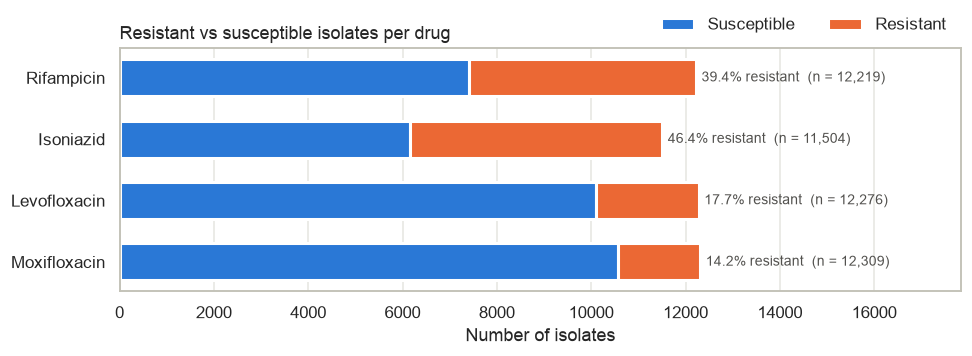

In [31]:
s = summary.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(s.index, s["susceptible"], color=C_S, height=0.6, label="Susceptible", edgecolor="white", linewidth=2)
ax.barh(s.index, s["resistant"], left=s["susceptible"], color=C_R, height=0.6, label="Resistant", edgecolor="white", linewidth=2)
for i, (name, row) in enumerate(s.iterrows()):
    ax.text(row["isolates"] + 120, i, f"{row['resistant_pct']:.1f}% resistant  (n = {int(row['isolates']):,})", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, s["isolates"].max() * 1.45)
ax.set_xlabel("Number of isolates")
ax.set_title("Resistant vs susceptible isolates per drug", loc="left")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), frameon=False, ncol=2)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Interpretation.** Rifampicin (39.4% resistant) and isoniazid (46.4%) are fairly balanced.
The fluoroquinolones are not: only 17.7% of isolates are resistant to levofloxacin and 14.2% to moxifloxacin.
A model that always predicts "susceptible" would score 82–86% accuracy on these drugs while missing every resistant patient.
We will therefore report sensitivity, specificity and precision-recall AUC rather than accuracy, and consider class weighting.

These resistance rates are much higher than in routine TB patients, because CRyPTIC deliberately collected drug-resistant isolates.
The data are therefore good for learning resistance mechanisms, but predictive values estimated on them would not carry over directly to a clinic population.

In addition, **4,191 isolates (36.9%) are MDR** (resistant to both rifampicin and isoniazid), and 93.1% of rifampicin-resistant isolates are also isoniazid-resistant.
This creates a shortcut risk: a rifampicin model given the full panel could "predict" rifampicin resistance from `katG` mutations.
We will compare target-gene-only models with full-panel models.

### Figure 2. MIC distributions and the resistance cut-off

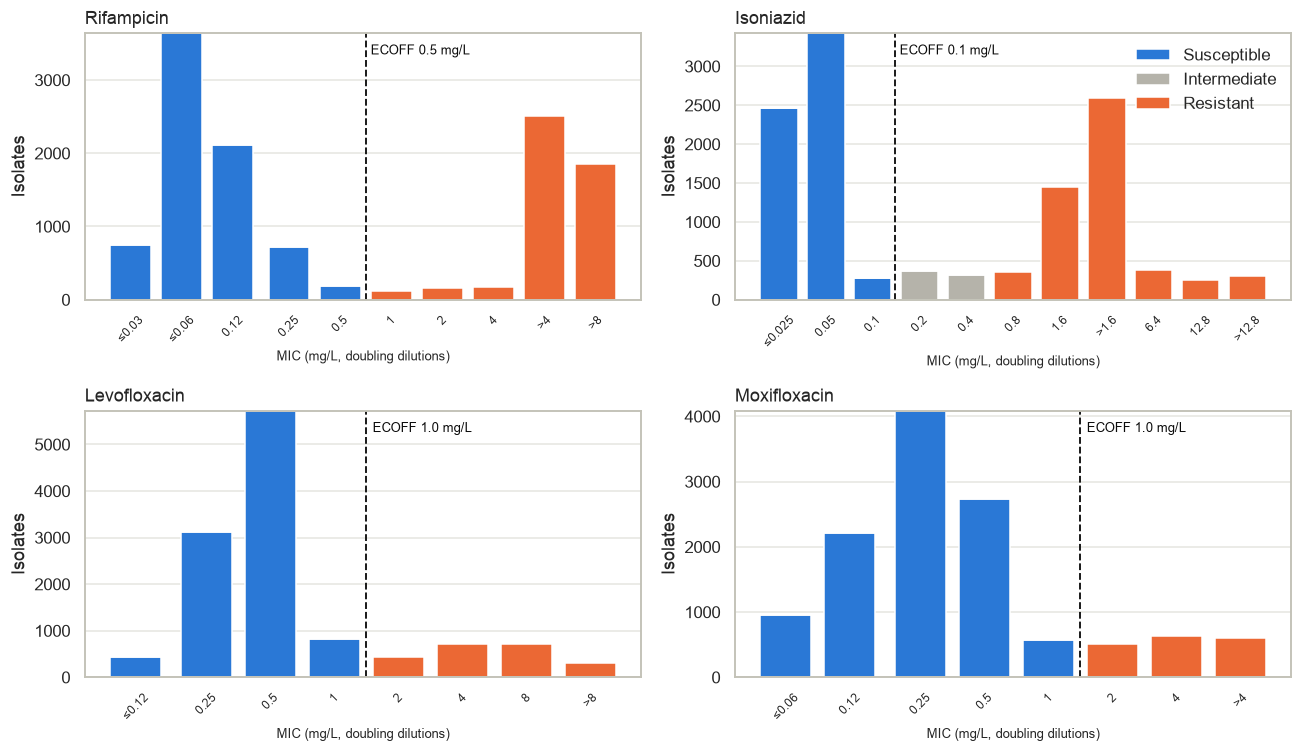

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, d in zip(axes.flat, DRUGS):
    sub = pheno4[(pheno4["DRUG"] == d) & pheno4["BINARY_PHENOTYPE"].isin(["R", "S", "I"])].copy()
    # a ">8" reading means at least the next dilution (16), so it is drawn one step to the right
    sub["xval"] = np.where(sub["MIC_CENSOR"] == ">", sub["MIC_VALUE"] * 2, sub["MIC_VALUE"])
    sub["x"] = np.log2(sub["xval"]).round(1)
    counts = sub.groupby(["x", "BINARY_PHENOTYPE"]).size().unstack(fill_value=0).reindex(columns=["S", "I", "R"], fill_value=0)
    bottom = np.zeros(len(counts))
    for lab_, col, name in [("S", C_S, "Susceptible"), ("I", "#b5b3aa", "Intermediate"), ("R", C_R, "Resistant")]:
        if counts[lab_].sum():
            ax.bar(counts.index, counts[lab_], bottom=bottom, width=0.8, color=col, label=name, edgecolor="white", linewidth=1)
            bottom += counts[lab_].values
    ax.axvline(np.log2(S_MAX[d]) + 0.5, color="#0b0b0b", ls="--", lw=1.2)
    ax.text(np.log2(S_MAX[d]) + 0.6, bottom.max() * 0.92, f"ECOFF {S_MAX[d]} mg/L", fontsize=8.5, color="#0b0b0b")
    def tick(g):
        val, cen = g["xval"].mode()[0], g["MIC_CENSOR"].mode()[0]
        return f">{val / 2:g}" if cen == ">" else (f"≤{val:g}" if cen == "<=" else f"{val:g}")
    ticks = sub.groupby("x").apply(tick, include_groups=False).reindex(counts.index)
    ax.set_xticks(counts.index.values)
    ax.set_xticklabels(ticks, rotation=45, fontsize=8)
    ax.set_title(DRUGS[d], loc="left")
    ax.set_xlabel("MIC (mg/L, doubling dilutions)", fontsize=8.5)
    ax.set_ylabel("Isolates")
    ax.grid(axis="x", visible=False)
axes[0, 1].legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

**Interpretation.** Each bar is one plate concentration. Censored readings are drawn at their bound (for example `>4` means the MIC is at least 8). The two plate designs have slightly different ranges, which is why some end bars mix `>4` and exact `8`.

* **Rifampicin and isoniazid** show two clearly separated groups: a susceptible (wild-type) peak at low MIC and a resistant peak several dilutions higher, with few isolates close to the ECOFF. Their binary labels should be reliable. The isoniazid *I* calls form the small valley between the two peaks.
* **Levofloxacin and moxifloxacin** look different. The resistant isolates are spread thinly over several dilutions, and many susceptible isolates sit exactly one dilution below the ECOFF (about 800 for levofloxacin and 560 for moxifloxacin at 1 mg/L). A one-dilution measurement error, which is common in broth microdilution, would flip their label. We therefore expect **more label noise for the fluoroquinolones**.

### Figure 3. Most resistance-associated mutations in each drug's target gene(s)

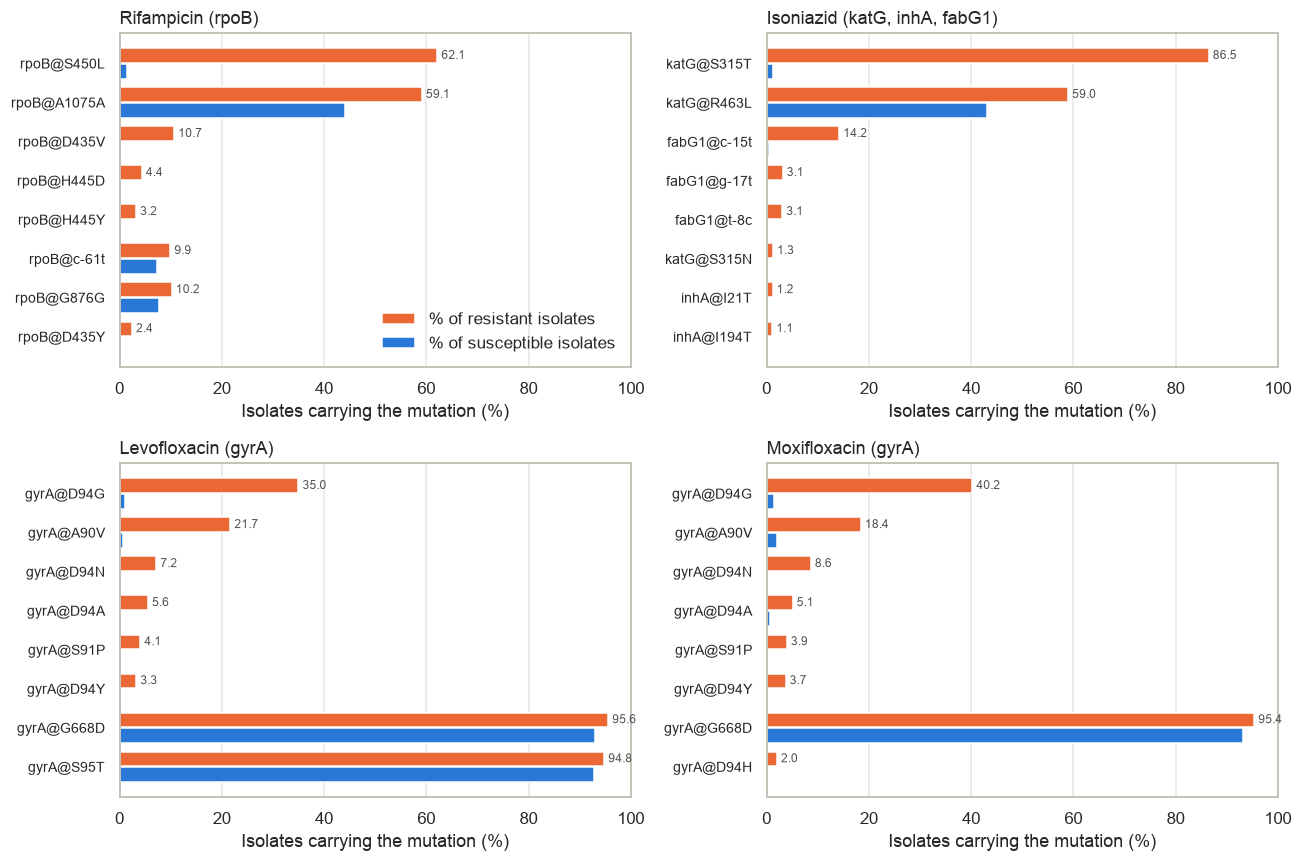

In [33]:
def enrichment(d):
    X, y = datasets[d]
    cols = feature_info.index[feature_info["GENE"].isin(TARGET_GENES[d])]
    res = pd.DataFrame({"pct_R": 100 * X.loc[y == 1, cols].mean(), "pct_S": 100 * X.loc[y == 0, cols].mean()})
    res["diff"] = res["pct_R"] - res["pct_S"]
    return res

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
top_tables = {}
for ax, d in zip(axes.flat, DRUGS):
    top = enrichment(d).sort_values("diff", ascending=False).head(8)
    top_tables[d] = top
    yy = np.arange(len(top))
    ax.barh(yy - 0.2, top["pct_R"], height=0.38, color=C_R, label="% of resistant isolates")
    ax.barh(yy + 0.2, top["pct_S"], height=0.38, color=C_S, label="% of susceptible isolates")
    for i, (r, s_) in enumerate(zip(top["pct_R"], top["pct_S"])):
        ax.text(r + 0.8, i - 0.2, f"{r:.1f}", va="center", fontsize=8, color="#52514e")
    ax.set_yticks(yy)
    ax.set_yticklabels(top.index, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_title(f"{DRUGS[d]} ({', '.join(TARGET_GENES[d])})", loc="left")
    ax.set_xlabel("Isolates carrying the mutation (%)")
    ax.grid(axis="y", visible=False)
axes[0, 0].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

In [34]:
# Mutations in the target genes that are common in SUSCEPTIBLE isolates (not resistance markers)
pd.concat({DRUGS[d]: enrichment(d).sort_values("pct_S", ascending=False).head(3).round(1) for d in ["RIF", "INH", "LEV"]})

pct_R  pct_S  diff
             feature                        
Rifampicin   rpoB@A1075A   59.1   44.1  15.1
             rpoB@D103D     4.4   13.6  -9.1
             rpoB@G876G    10.2    7.7   2.5
Isoniazid    katG@R463L    59.0   43.2  15.8
             inhA@G3G       0.9    1.3  -0.4
             katG@S315T    86.5    1.2  85.2
Levofloxacin gyrA@E21Q     99.9   99.9   0.0
             gyrA@G668D    95.6   93.0   2.6
             gyrA@S95T     94.8   92.8   2.0

**Interpretation.** Each drug's resistance is dominated by a few well-known mutations, matching the WHO mutation catalogue [2]:

* **Rifampicin:** `rpoB@S450L` is found in 62.1% of resistant isolates and almost no susceptible ones. It is followed by `D435V` (10.7%) and changes at codon 445. All of these lie in the RRDR.
* **Isoniazid:** `katG@S315T` alone is found in 86.5% of resistant isolates against 1.2% of susceptible ones. The `fabG1` promoter mutation `c-15t` adds 14.2%.
* **Fluoroquinolones:** `gyrA` codons 94 (`D94G`, `D94N`, `D94A`, `D94Y`) and 90 (`A90V`) account for most resistance.

The plot also shows a trap. `rpoB@A1075A`, `katG@R463L`, `gyrA@G668D` and `gyrA@S95T` are common in **both** groups (the table above).
They look mildly "enriched" in resistant isolates only because they are lineage markers, and some lineages have more resistance (see Figure 5).
A model could give them weight even though they have nothing to do with resistance.

### Figure 4. Can the target genes explain resistance?

For each drug we compare the share of resistant and susceptible isolates that carry at least one mutation in the drug's target gene(s), defined in two ways:

* **Left:** any missense, nonsense, promoter or indel mutation anywhere in the target gene(s). Synonymous changes are left out because they do not change the protein.
* **Right:** only mutations in the known resistance hotspots [2]: the rpoB rifampicin-resistance-determining region (RRDR, codons 426–452); katG codon 315 or the fabG1–inhA promoter; and the gyrA quinolone-resistance-determining region (QRDR, codons 88–94).

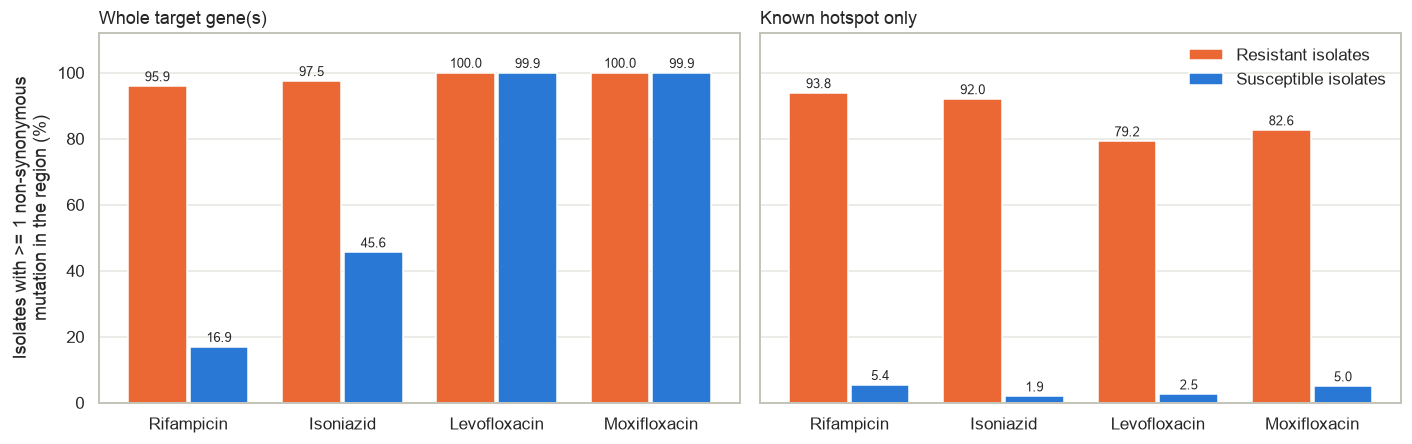

Resistant                             Susceptible                     
region       Known hotspot only Whole target gene(s) Known hotspot only Whole target gene(s)
drug                                                                                        
Rifampicin                 93.8                 95.9                5.4                 16.9
Isoniazid                  92.0                 97.5                1.9                 45.6
Levofloxacin               79.2                100.0                2.5                 99.9
Moxifloxacin               82.6                100.0                5.0                 99.9

In [35]:
HOTSPOT = {
    "RIF": (feature_info["GENE"] == "rpoB") & feature_info["codon"].between(426, 452),
    "INH": ((feature_info["GENE"] == "katG") & (feature_info["codon"] == 315)) | (feature_info["GENE"] == "fabG1"),
    "LEV": (feature_info["GENE"] == "gyrA") & feature_info["codon"].between(88, 94),
}
HOTSPOT["MXF"] = HOTSPOT["LEV"]
nonsyn = feature_info["mut_class"] != "synonymous"

rows = []
for d in DRUGS:
    X, y = datasets[d]
    for region, mask in [("Whole target gene(s)", feature_info["GENE"].isin(TARGET_GENES[d]) & nonsyn),
                         ("Known hotspot only", HOTSPOT[d] & nonsyn)]:
        has = X[feature_info.index[mask]].sum(axis=1) > 0
        rows.append({"drug": DRUGS[d], "region": region,
                     "Resistant": 100 * has[y == 1].mean(), "Susceptible": 100 * has[y == 0].mean()})
burden = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, region in zip(axes, ["Whole target gene(s)", "Known hotspot only"]):
    b = burden[burden["region"] == region].set_index("drug")
    xx = np.arange(len(b))
    ax.bar(xx - 0.2, b["Resistant"], width=0.38, color=C_R, label="Resistant isolates")
    ax.bar(xx + 0.2, b["Susceptible"], width=0.38, color=C_S, label="Susceptible isolates")
    for i, (r, s_) in enumerate(zip(b["Resistant"], b["Susceptible"])):
        ax.text(i - 0.2, r + 1.5, f"{r:.1f}", ha="center", fontsize=8.5)
        ax.text(i + 0.2, s_ + 1.5, f"{s_:.1f}", ha="center", fontsize=8.5)
    ax.set_xticks(xx)
    ax.set_xticklabels(b.index)
    ax.set_ylim(0, 112)
    ax.set_title(region, loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Isolates with >= 1 non-synonymous\nmutation in the region (%)")
axes[1].legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()
burden.pivot(index="drug", columns="region", values=["Resistant", "Susceptible"]).round(1).loc[list(DRUGS.values())]

**Interpretation.**

* **Left (whole gene):** almost every resistant isolate has a non-synonymous mutation somewhere in its target gene, but so do 17% (RIF), 46% (INH) and 99.9% (LEV/MXF) of susceptible isolates. "Any mutation in the gene" is therefore a poor predictor, because of the lineage markers found above.
* **Right (known hotspots):** restricting to the RRDR, `katG` 315 + `fabG1` promoter, and the QRDR separates the groups sharply. For rifampicin: 93.8% of resistant vs 5.4% of susceptible isolates. For isoniazid: 92.0% vs 1.9%. This suggests the panel can predict first-line resistance well.
* For the fluoroquinolones, **about 17–21% of resistant isolates have no QRDR mutation**. Possible causes include mutations elsewhere in `gyrA`, mechanisms outside our panel (for example `gyrB`), and the borderline-MIC label noise seen in Figure 2. We therefore expect lower sensitivity for levofloxacin and moxifloxacin than for rifampicin and isoniazid.

### Figure 5. Resistance prevalence by lineage

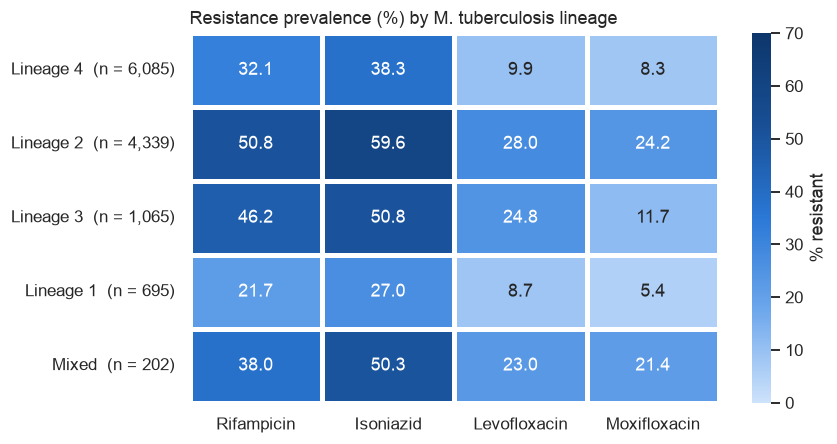

In [36]:
lin_tab = lab[lab["lineage"].isin(lin.index[lin["isolates"] >= 100])]
prev = lin_tab.pivot_table(index="lineage", columns="DRUG", values="label", aggfunc="mean").mul(100)[list(DRUGS)]
n_lin = lin_tab.drop_duplicates("UNIQUEID")["lineage"].value_counts()
prev = prev.loc[n_lin.index]
prev.index = [f"{l}  (n = {n_lin[l]:,})" for l in prev.index]
prev.columns = [DRUGS[c] for c in prev.columns]

blues = sns.blend_palette(["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"], as_cmap=True)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(prev, annot=True, fmt=".1f", cmap=blues, vmin=0, vmax=70, linewidths=2, linecolor="white",
            cbar_kws={"label": "% resistant"}, ax=ax)
ax.set_title("Resistance prevalence (%) by M. tuberculosis lineage", loc="left")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [37]:
# Are the "common in susceptible" mutations from Figure 3 lineage markers? (% of isolates in each lineage carrying them)
markers = ["katG@R463L", "rpoB@A1075A", "gyrA@S95T", "gyrA@G668D"]
major = cohort["lineage"].isin(["Lineage 1", "Lineage 2", "Lineage 3", "Lineage 4"])
X_all.loc[major, markers].groupby(cohort.loc[major, "lineage"]).mean().mul(100).round(1)

feature,katG@R463L,rpoB@A1075A,gyrA@S95T,gyrA@G668D
lineage,,,,
Lineage 1,99.7,99.7,99.9,100.0
Lineage 2,99.6,99.8,99.5,100.0
Lineage 3,99.3,99.9,99.7,99.9
Lineage 4,0.0,0.0,86.9,87.0


**Interpretation.** Resistance varies strongly by lineage: lineage 2 (which includes the Beijing family) is 50.8% rifampicin-resistant and 28.0% levofloxacin-resistant, compared with 21.7% and 8.7% for lineage 1.
The table above confirms that `katG@R463L` and `rpoB@A1075A` are found in about 99.5% of lineage 1–3 isolates and in **none** of lineage 4, which is the lineage of the H37Rv reference genome.
These two features therefore encode lineage, and because lineage is linked to resistance, they appear predictive.

**Consequence for the modelling stage:** a random train/test split would let a model score well partly by recognising lineage.
We will (1) check whether lineage-marker features receive weight, and (2) evaluate with lineage-aware cross-validation (for example, training on some lineages and testing on another) to measure how well the models generalise.

## 3.4 Summary

**Main characteristics of the dataset.**
CRyPTIC `release_june2022` links whole-genome variant calls to broth-microdilution MICs.
After joining and cleaning, it provides **12,477 *M. tuberculosis* isolates** and a binary isolate × mutation matrix with **1,553 distinct mutations** in `rpoB`, `katG`, `inhA`, the `fabG1` promoter and `gyrA`.
Per-drug cohorts range from 11,504 (isoniazid) to 12,309 (moxifloxacin) isolates.
Lineages 4 (49%) and 2 (35%) dominate. Isolates come from at least 21 countries, with South Africa the only large African source (1,640 isolates) and **none from Kenya**.

**Data-quality issues and how we handled them.**
* No duplicate records, but **390 patients have multiple isolates** → patient-grouped train/test splits.
* MIC stored as mixed text with censored values → parsed into a value and a direction. The R/S/I labels agree 100% with the MIC + ECOFF rule.
* Join keys with **inconsistent types** across tables (`SITEID` int vs text) → read as text.
* Text-encoded booleans → converted. Mutation names classified into missense, synonymous, promoter, nonsense, indel and null.
* Irrelevant records removed: 10 other drugs, isolates lacking a genome or a phenotype, 14 non-*M. tuberculosis* isolates, mutations outside the panel.
* Missing phenotypes (911) and isoniazid *I* calls (686) dropped per drug. Missing country labelled "Unknown". **Null genotype calls (713 isolates) kept as "unknown" in a separate mask** instead of being treated as wild type.

**Most important patterns.**
1. **Class imbalance** for the fluoroquinolones (14–18% resistant) vs near-balance for rifampicin/isoniazid (39–46%).
2. **A few hotspot mutations explain most resistance:** `rpoB` S450L (62% of RIF-R), `katG` S315T (87% of INH-R), `gyrA` D94/A90. Known hotspots cover 92–94% of first-line resistance but only 79–83% of fluoroquinolone resistance.
3. **The fluoroquinolone phenotypes are less clear-cut:** many MICs sit one dilution from the ECOFF.
4. **Lineage confounding:** some common mutations are pure lineage markers, and resistance rates differ more than twofold between lineages.
5. **Extreme sparsity:** 62% of mutations occur in only one isolate.
6. **Strong co-resistance:** 36.9% of isolates are MDR.

**How this informs the next stage.**
* Train one classifier per drug: L1-regularised logistic regression (interpretable, suits a few strong features) and random forest.
* Use patient-grouped and lineage-aware splits. Fit any frequency filter on the training folds only.
* Report sensitivity, specificity and PR-AUC rather than accuracy.
* Compare target-gene-only vs full-panel feature sets to detect co-resistance shortcuts.
* Decide how to treat null calls at hotspot sites (as 0, as a separate indicator, or drop the isolate).
* Compare the models with a rule-based WHO catalogue lookup.

**Limitations.**
* The panel misses resistance mechanisms outside the five genes (for example `gyrB`, efflux pumps), which caps fluoroquinolone sensitivity.
* Pyrazinamide cannot be studied: it is not on the UKMYC plates.
* ECOFF-based labels separate wild-type from non-wild-type isolates, which is not the same as clinical breakpoints.
* The resistance prevalence is enriched by design, and there are no Kenyan isolates, so results may not transfer directly to Kenyan or East African TB programmes.
* About a fifth of phenotypes are LOW quality. Mixed infections cannot be detected from `MUTATIONS`. Associations seen here are correlational, not proof of causation.

## References

1. World Health Organization. *Global Tuberculosis Report 2025*. Geneva: WHO; 2025. https://www.who.int/teams/global-tuberculosis-programme/tb-reports/global-tuberculosis-report-2025
2. World Health Organization. *Catalogue of mutations in Mycobacterium tuberculosis complex and their association with drug resistance*, 2nd edition. Geneva: WHO; 2023.
3. Walker TM, Kohl TA, Omar SV, et al. Whole-genome sequencing for prediction of *Mycobacterium tuberculosis* drug susceptibility and resistance: a retrospective cohort study. *Lancet Infectious Diseases*. 2015;15(10):1193–1202.
4. The CRyPTIC Consortium. A data compendium associating the genomes of 12,289 *Mycobacterium tuberculosis* isolates with quantitative resistance phenotypes to 13 antibiotics. *PLoS Biology*. 2022;20(8):e3001721. https://doi.org/10.1371/journal.pbio.3001721. Data: https://ftp.ebi.ac.uk/pub/databases/cryptic/release_june2022/
5. The CRyPTIC Consortium. Epidemiological cutoff values for a 96-well broth microdilution plate for high-throughput research antibiotic susceptibility testing of *M. tuberculosis*. *European Respiratory Journal*. 2022;60(4):2200239. https://doi.org/10.1183/13993003.00239-2022
6. Hunt M, Bradley P, Lapierre SG, et al. Antibiotic resistance prediction for *Mycobacterium tuberculosis* from genome sequence data with Mykrobe. *Wellcome Open Research*. 2019;4:191. (Source of the lineage calls in `GENOMES`.)